# 04 · ML outcome model: BankSight

**Goal:** build the best honest model of `got_relief`, decide whether the extra complexity is worth it, make its probabilities trustworthy,
and turn it into a decision rule. Everything is fitted on **train**; **validation** is used for comparison, calibration and thresholds;
the **test** period stays sealed for the final evaluation.

**Steps**
1. Tune the text model's regularisation with time-ordered folds (never a random split).
2. Build out-of-fold text scores so a boosted model can use text without seeing in-sample predictions (stacking).
3. Train LightGBM and XGBoost on identical inputs, tuning budget and folds, and compare them with a paired bootstrap.
4. Company-name ablation: how much of the text lift survives when company names are masked?
5. Pick a champion by a stated rule (a complex model must earn its place over logistic regression).
6. Calibrate the probabilities, set a cost-based threshold, and report lift by top-k% of complaints.
7. Explain the boosted model with SHAP, log to MLflow, and save the artefacts.

**What this does:** loads every library and sets file paths and the settings used later. All imports live in this one cell. The `COST_FP` and
`BENEFIT_TP` numbers are business assumptions (not data) that you should edit.

In [1]:
import json
import re
import time
import warnings
from pathlib import Path

import duckdb
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import xgboost as xgb
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*eval_set.*")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4g}".format)

In [2]:
ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
WAREHOUSE = ROOT / "data" / "warehouse" / "banksight.duckdb"
REPORT_DIR = ROOT / "reports" / "data_quality"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for folder in (REPORT_DIR, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)
assert WAREHOUSE.exists(), "Run notebooks 01 and 01b first."

SEED = 42
N_BOOT = 300
N_ITER_SEARCH = 12            # random-search configurations per boosted model
C_GRID = (0.3, 1.0, 3.0)      # text-logistic regularisation candidates
# Business assumptions for the decision rule (EDIT THESE; they are assumptions, not data):
COST_FP = 1.0                 # cost of flagging a complaint that ends WITHOUT relief
BENEFIT_TP = 3.0              # benefit of flagging a complaint that DOES end with relief

## 1. Load train + validation
Sorted by `date_received`, so "first 80% of rows" always means "earlier in time".

**What this does:** reads complaints from the DuckDB warehouse, keeping only train and validation rows that have a narrative. The `issue` column
is optional, so we check whether it exists first.

In [3]:
con = duckdb.connect(str(WAREHOUSE), read_only=True)
column_rows = con.sql(
    "SELECT column_name FROM information_schema.columns WHERE table_schema='raw' AND table_name='cfpb_complaints'").fetchall()
have_cols = set()
for column_row in column_rows:
    have_cols.add(column_row[0])
issue_sql = "r.issue" if "issue" in have_cols else "NULL"
df = con.sql(f"""
    SELECT l.complaint_id, l.date_received, l.product_group, l.got_relief, l.split,
           {issue_sql} AS issue, r.narrative
    FROM features.complaint_labels l
    JOIN raw.cfpb_complaints r USING (complaint_id)
    WHERE l.target_eligible AND l.split IN ('train', 'validation')
      AND r.narrative IS NOT NULL AND length(trim(r.narrative)) > 0
""").df()
con.close()

**What this does:** tidies the types, splits into train and validation, and sorts each by date (oldest first). We print sizes and the share of
complaints that ended with relief.

In [4]:
df["got_relief"] = df["got_relief"].astype(int)
df["issue"] = df["issue"].fillna("Unknown").astype(str)
df["date_received"] = pd.to_datetime(df["date_received"])
tr = df[df.split == "train"].sort_values("date_received", kind="stable").reset_index(drop=True)
va = df[df.split == "validation"].sort_values("date_received", kind="stable").reset_index(drop=True)
del df
y_tr = tr.got_relief.to_numpy()
y_va = va.got_relief.to_numpy()
print(f"train {len(tr):,} ({tr.date_received.min().date()} to {tr.date_received.max().date()}) | "
      f"validation {len(va):,} ({va.date_received.min().date()} to {va.date_received.max().date()})")
print(f"relief rate: train {y_tr.mean():.2%} | validation {y_va.mean():.2%}")

train 103,777 (2023-01-01 to 2025-06-30) | validation 18,537 (2025-07-01 to 2025-10-31)
relief rate: train 23.70% | validation 22.78%


## 2. Clean the text and build TF-IDF
Same cleaning as notebook 03 (amounts, dates and `XXXX` masks become neutral tokens). The vectorizer is fitted on **train only**.

**What this does:** replaces dollar amounts, dates and `XXXX` privacy masks with neutral words (`amtmask`, `datemask`, `xmask`) so the model
does not memorise specific numbers, then squeezes repeated spaces. The regex strings are kept in variables because they are saved in the bundle.

In [5]:
RE_AMT = r"\{\$[\d,\.]+\}|\$\s?[\d,]+(?:\.\d+)?"
RE_DATE = r"\bXX/XX/(?:XXXX|\d{2,4})\b|\bXX/\d{2}/\d{2,4}\b"
RE_MASK = r"\bX{2,}\b"

text_tr = tr.narrative.str.replace(RE_AMT, " amtmask ", regex=True)
text_tr = text_tr.str.replace(RE_DATE, " datemask ", regex=True)
text_tr = text_tr.str.replace(RE_MASK, " xmask ", regex=True)
tr["text"] = text_tr.str.replace(r"\s+", " ", regex=True).str.strip()

text_va = va.narrative.str.replace(RE_AMT, " amtmask ", regex=True)
text_va = text_va.str.replace(RE_DATE, " datemask ", regex=True)
text_va = text_va.str.replace(RE_MASK, " xmask ", regex=True)
va["text"] = text_va.str.replace(r"\s+", " ", regex=True).str.strip()

tr = tr.drop(columns="narrative")
va = va.drop(columns="narrative")

**What this does:** turns each complaint into numbers with **TF-IDF**: every word or word pair gets a weight that is high when the term is
frequent in that complaint but rare overall. The vocabulary is learned on train only and then applied to validation.

In [6]:
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=150_000, dtype=np.float32)
Xtr_t = tfidf.fit_transform(tr.text).tocsr()
Xva_t = tfidf.transform(va.text).tocsr()
print(f"TF-IDF {Xtr_t.shape} in {time.time() - t0:.0f}s")

TF-IDF (103777, 150000) in 70s


## 3. Tune the text model with time-ordered folds
Train is cut into 4 consecutive time chunks. Each fold trains on the chunks **before** a chunk and tests on that chunk
(expanding window), which mimics "train on the past, predict the future". The best `C` is the one with the highest mean PR-AUC.
(The vocabulary was fitted on all of train; that is unsupervised and a very small leak, accepted here.)

**What this does:** tries three regularisation strengths `C` for a logistic regression (smaller `C` means a simpler, more cautious model). We use
**time-ordered folds**: always train on earlier chunks and test on the next one. The score is **PR-AUC** (average precision): how well the model
ranks relief cases near the top, which suits an imbalanced outcome.

In [7]:
t0 = time.time()
chunks = np.array_split(np.arange(len(tr)), 4)
rows = []
for C in C_GRID:
    fold_scores = []
    for k in range(1, 4):
        train_idx = np.concatenate(chunks[:k])
        test_idx = chunks[k]
        model = LogisticRegression(C=C, solver="liblinear", max_iter=200, random_state=SEED).fit(Xtr_t[train_idx], y_tr[train_idx])
        fold_scores.append(average_precision_score(y_tr[test_idx], model.predict_proba(Xtr_t[test_idx])[:, 1]))
    rows.append({"C": C, "fold1": fold_scores[0], "fold2": fold_scores[1], "fold3": fold_scores[2],
                 "mean_pr_auc": float(np.mean(fold_scores))})
print(f"done in {time.time() - t0:.0f}s")

done in 113s


**What this does:** puts the fold scores in a table, picks the `C` with the best mean PR-AUC, and saves the table.

In [8]:
tune = pd.DataFrame(rows).set_index("C")
BEST_C = float(tune.mean_pr_auc.idxmax())
display(tune)
print("chosen C =", BEST_C)
tune.to_csv(REPORT_DIR / "04_tuning_text_C.csv")

,fold1,fold2,fold3,mean_pr_auc
C,,,,
0.3,0.5412,0.4632,0.4873,0.4972
1,0.5434,0.4795,0.5016,0.5082
3,0.5348,0.48,0.5014,0.5054


chosen C = 1.0


## 4. Out-of-fold text scores (stacking input)
A boosted model that is trained on text scores must never see scores the text model produced **on its own training rows** (they are over-confident).
So train is split into 5 consecutive **blocks**; each block is scored by a text model fitted on the other 4 blocks.
Validation is scored by the text model fitted on all of train.

**What this does:** builds **out-of-fold (OOF)** scores: every training complaint is scored by a text model that never saw it. These honest scores
become an input for the boosted models (this is called **stacking**: one model's output feeds the next).

In [9]:
t0 = time.time()
blocks = np.array_split(np.arange(len(tr)), 5)
oof = np.zeros(len(tr))
for block in blocks:
    keep = np.ones(len(tr), bool)
    keep[block] = False
    model = LogisticRegression(C=BEST_C, solver="liblinear", max_iter=200, random_state=SEED).fit(Xtr_t[keep], y_tr[keep])
    oof[block] = model.predict_proba(Xtr_t[block])[:, 1]
print(f"done in {time.time() - t0:.0f}s")

done in 99s


**What this does:** fits the text model on all of train and scores validation. These are the validation text scores used everywhere below.

In [10]:
text_full = LogisticRegression(C=BEST_C, solver="liblinear", max_iter=200, random_state=SEED).fit(Xtr_t, y_tr)
p_text_va = text_full.predict_proba(Xva_t)[:, 1]
print(f"OOF PR-AUC on train {average_precision_score(y_tr, oof):.3f} | validation PR-AUC {average_precision_score(y_va, p_text_va):.3f}")

OOF PR-AUC on train 0.519 | validation PR-AUC 0.421


## 5. Feature frame for the boosted models
Five inputs only: the out-of-fold **text score**, **product**, **issue** (rare issues pooled into one bucket), **log2 word count** and the
**number of dollar amounts** mentioned. Notebook 02 found narrative length uninformative, so `log_words` is included as a check.

**What this does:** lists the allowed product and issue categories (issues with fewer than 50 train complaints are pooled into one bucket, so the
model does not chase rare labels).

In [11]:
issue_counts = tr.issue.value_counts()
POOL = "Other (pooled)"
ISSUE_CATS = sorted(issue_counts[issue_counts >= 50].index.tolist()) + [POOL]
PRODUCT_CATS = sorted(tr.product_group.unique().tolist())
print(len(ISSUE_CATS) - 1, "issues kept,", len(PRODUCT_CATS), "products")

65 issues kept, 10 products


**What this does:** builds the five-column table for train and validation. The text score is moved to the log-odds scale (`log(p / (1-p))`) after
clipping, which gives trees a better-spread input.

In [12]:
score_tr = np.clip(oof, 1e-4, 1 - 1e-4)
issue_tr = tr.issue.where(tr.issue.isin(ISSUE_CATS), POOL)
Ftr = pd.DataFrame({
    "text_score": np.log(score_tr / (1 - score_tr)),
    "product_group": pd.Categorical(tr.product_group, categories=PRODUCT_CATS),
    "issue": pd.Categorical(issue_tr, categories=ISSUE_CATS),
    "log_words": np.log2(tr.text.str.count(r"\S+").clip(lower=1)),
    "n_amounts": tr.text.str.count("amtmask"),
})

score_va = np.clip(p_text_va, 1e-4, 1 - 1e-4)
issue_va = va.issue.where(va.issue.isin(ISSUE_CATS), POOL)
Fva = pd.DataFrame({
    "text_score": np.log(score_va / (1 - score_va)),
    "product_group": pd.Categorical(va.product_group, categories=PRODUCT_CATS),
    "issue": pd.Categorical(issue_va, categories=ISSUE_CATS),
    "log_words": np.log2(va.text.str.count(r"\S+").clip(lower=1)),
    "n_amounts": va.text.str.count("amtmask"),
})
print(Ftr.dtypes.to_string())

text_score        float64
product_group    category
issue            category
log_words         float64
n_amounts           int64


## 6. LightGBM and XGBoost: same inputs, same folds, same budget
Random search over 12 configurations each. Each candidate is trained on the first 80% of train (by time) with early stopping on the last 20%,
and scored by PR-AUC on that last 20%. The best configuration is then **refitted on all of train** with the number of trees found by early stopping.
No class re-weighting: it would distort the probabilities that calibration needs later.

**What this does:** splits train in time (first 80% to fit, last 20% to judge) and creates the random generator for the search. **LightGBM** and
**XGBoost** are two popular libraries that build many small decision trees, each correcting the previous ones' mistakes.

In [13]:
cut = int(len(tr) * 0.8)
Fa, Fb = Ftr.iloc[:cut], Ftr.iloc[cut:]
ya, yb = y_tr[:cut], y_tr[cut:]
rng = np.random.default_rng(SEED)

**What this does:** **random search** tries 12 random settings for LightGBM (tree size, learning speed and so on) and keeps the best. **Early
stopping** halts adding trees once the judging score has not improved for 50 rounds, which tells us how many trees are enough.

In [14]:
best_lgb_score = -1
best_lgb_params = None
best_lgb_trees = None
lgb_log = []
for i in range(N_ITER_SEARCH):
    params = {
        "num_leaves": int(rng.choice([7, 15, 31])),
        "learning_rate": float(rng.choice([0.03, 0.05, 0.1])),
        "min_child_samples": int(rng.choice([50, 100, 300])),
        "subsample": float(rng.choice([0.7, 0.85, 1.0])),
        "colsample_bytree": float(rng.choice([0.7, 1.0])),
        "reg_lambda": float(rng.choice([0, 1, 10])),
    }
    model = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, verbose=-1, n_jobs=4, **params)
    model.fit(Fa, ya, eval_set=[(Fb, yb)], eval_metric="average_precision", callbacks=[lgb.early_stopping(50, verbose=False)])
    n_trees = int(model.best_iteration_ or 1)
    score = average_precision_score(yb, model.predict_proba(Fb)[:, 1])
    log_row = dict(params)
    log_row["n_trees"] = n_trees
    log_row["inner_pr_auc"] = score
    lgb_log.append(log_row)
    if score > best_lgb_score:
        best_lgb_score = score
        best_lgb_params = params
        best_lgb_trees = n_trees

**What this does:** the same random search for XGBoost (12 settings, same early stopping), continuing with the same random generator.

In [15]:
best_xgb_score = -1
best_xgb_params = None
best_xgb_trees = None
xgb_log = []
for i in range(N_ITER_SEARCH):
    params = {
        "max_depth": int(rng.choice([2, 3, 4, 5])),
        "learning_rate": float(rng.choice([0.03, 0.05, 0.1])),
        "min_child_weight": float(rng.choice([1, 5, 20])),
        "subsample": float(rng.choice([0.7, 0.85, 1.0])),
        "colsample_bytree": float(rng.choice([0.7, 1.0])),
        "reg_lambda": float(rng.choice([1, 5, 20])),
    }
    model = xgb.XGBClassifier(n_estimators=2000, tree_method="hist", enable_categorical=True, eval_metric="aucpr",
                              early_stopping_rounds=50, random_state=SEED, n_jobs=4, **params)
    model.fit(Fa, ya, eval_set=[(Fb, yb)], verbose=False)
    n_trees = int(model.best_iteration) + 1
    score = average_precision_score(yb, model.predict_proba(Fb)[:, 1])
    log_row = dict(params)
    log_row["n_trees"] = n_trees
    log_row["inner_pr_auc"] = score
    xgb_log.append(log_row)
    if score > best_xgb_score:
        best_xgb_score = score
        best_xgb_params = params
        best_xgb_trees = n_trees

**What this does:** ranks the tried settings by score, shows the top three of each model, and saves the full search logs.

In [16]:
log_lgb = pd.DataFrame(lgb_log).sort_values("inner_pr_auc", ascending=False)
log_xgb = pd.DataFrame(xgb_log).sort_values("inner_pr_auc", ascending=False)
print("LightGBM top configs")
display(log_lgb.head(3))
print("XGBoost top configs")
display(log_xgb.head(3))
log_lgb.to_csv(REPORT_DIR / "04_search_lightgbm.csv", index=False)
log_xgb.to_csv(REPORT_DIR / "04_search_xgboost.csv", index=False)

LightGBM top configs


,num_leaves,learning_rate,min_child_samples,subsample,colsample_bytree,reg_lambda,n_trees,inner_pr_auc
8,31,0.1,300,0.7,0.7,1,10,0.518
2,31,0.1,300,1,1,0,40,0.5174
5,15,0.03,50,0.85,1,0,64,0.5173


XGBoost top configs


,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,n_trees,inner_pr_auc
8,3,0.1,5,0.85,1,5,55,0.5168
1,4,0.1,20,0.85,0.7,20,116,0.5165
3,3,0.1,20,0.85,1,1,55,0.5165


**What this does:** refits each best configuration on all of train, using 10% more trees than early stopping found (there is more data now),
then predicts validation.

In [17]:
n_l = int(best_lgb_trees * 1.1) + 1
n_x = int(best_xgb_trees * 1.1) + 1
lgbm = lgb.LGBMClassifier(n_estimators=n_l, subsample_freq=1, random_state=SEED, verbose=-1, n_jobs=4, **best_lgb_params).fit(Ftr, y_tr)
xgbm = xgb.XGBClassifier(n_estimators=n_x, tree_method="hist", enable_categorical=True, eval_metric="aucpr",
                         early_stopping_rounds=None, random_state=SEED, n_jobs=4, **best_xgb_params).fit(Ftr, y_tr)
p_lgb = lgbm.predict_proba(Fva)[:, 1]
p_xgb = xgbm.predict_proba(Fva)[:, 1]
print(f"refit on all train: LightGBM {n_l} trees, XGBoost {n_x} trees")

refit on all train: LightGBM 12 trees, XGBoost 61 trees


## 7. Company-name ablation
Notebook 03's top terms were mostly company names. A consumer names the company when filing, so using it is allowed, but it matters whether the
model learned **what happened** or only **who the company is**. We mask a list of well-known company names with a neutral token, refit the same
text model, and see how much lift survives. The list is **not exhaustive**, so the result is a *lower bound* on the company effect. If the printed
top terms of the masked model still show company names, add them to `EXTRA_COMPANY_TERMS` and re-run this section.

**What this does:** defines the company names to hide and compiles them into one case-insensitive pattern (longest names first so "wells fargo"
is matched before "wells"). Then it reports how many narratives mention at least one listed company.

In [18]:
COMPANY_TERMS = [
    "transunion", "trans union", "experian", "equifax", "citi", "citibank", "citigroup", "comenity", "credence", "credence resource management",
    "midland", "midland credit", "portfolio recovery", "encore capital", "lvnv", "jefferson capital", "convergent", "enhanced recovery",
    "transworld", "wells fargo", "bank of america", "boa", "chase", "jpmorgan", "capital one", "discover", "synchrony", "amex",
    "american express", "us bank", "td bank", "td", "pnc", "truist", "navy federal", "usaa", "paypal", "venmo", "cash app", "cashapp",
    "zelle", "robinhood", "coinbase", "affirm", "klarna", "chime", "sofi", "ally", "barclays", "netspend", "direct express", "green dot",
    "huntington", "regions", "fifth third", "citizens", "keybank", "santander", "lendingclub", "upstart", "avant", "onemain", "mr cooper",
    "rocket mortgage", "quicken", "lakeview", "freedom mortgage", "nationstar", "nelnet", "navient", "mohela", "great lakes", "fedloan",
    "aidvantage", "carmax", "ford credit", "toyota financial", "gm financial", "westlake", "vanilla", "bluevine", "merrick", "credit one",
]
EXTRA_COMPANY_TERMS = []   # add names you spot in the masked model's top terms, then re-run this section

all_terms = list(COMPANY_TERMS)
for extra_term in EXTRA_COMPANY_TERMS:
    all_terms.append(extra_term.lower())
terms = sorted(set(all_terms), key=len, reverse=True)
escaped_terms = []
for term in terms:
    escaped_terms.append(re.escape(term))
RE_COMPANY = re.compile(r"\b(?:" + "|".join(escaped_terms) + r")\b", re.IGNORECASE)

touch_tr = tr.text.str.contains(RE_COMPANY).mean()
touch_va = va.text.str.contains(RE_COMPANY).mean()
print(f"narratives containing at least one listed company name: train {touch_tr:.1%} | validation {touch_va:.1%}")

narratives containing at least one listed company name: train 46.8% | validation 42.7%


**What this does:** replaces every listed company name with `companymask`, rebuilds TF-IDF on the masked text, and refits the text model with the
same tuned `C`.

In [19]:
t0 = time.time()
trm = tr.text.str.replace(RE_COMPANY, " companymask ", regex=True)
vam = va.text.str.replace(RE_COMPANY, " companymask ", regex=True)
tfidf_m = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=150_000, dtype=np.float32)
Xtr_m = tfidf_m.fit_transform(trm).tocsr()
Xva_m = tfidf_m.transform(vam).tocsr()
text_masked = LogisticRegression(C=BEST_C, solver="liblinear", max_iter=200, random_state=SEED).fit(Xtr_m, y_tr)
p_masked = text_masked.predict_proba(Xva_m)[:, 1]
print(f"masked model fitted in {time.time() - t0:.0f}s")

masked model fitted in 161s


**What this does:** prints the 25 terms the masked model links most strongly to relief and to a plain explanation, so you can spot company names
that slipped through.

In [20]:
mterms = np.array(tfidf_m.get_feature_names_out())
mcoef = text_masked.coef_[0]
order_m = np.argsort(mcoef)
print("Top terms after masking, towards RELIEF:   ", ", ".join(mterms[order_m[::-1][:25]]))
print("Top terms after masking, towards EXPLANATION:", ", ".join(mterms[order_m[:25]]))

Top terms after masking, towards RELIEF:    companymask management, credit, accounts, bofa, card, late, fee, inaccuracies, calling, calls, mcm, capio, cbe, report, inaccurate, xmask xmask, companymask resource, southwest credit, these, resource, noticed, travel, late fee, bmo, southwest
Top terms after masking, towards EXPLANATION: loan, mortgage, inc, loans, was, systems, finance, companymask systems, money, forbearance, funds, financial, foreclosure, student, school, marcus, servicing, llc, edfinancial, services, square, debit, recovery, my loans, national credit


## 8. Compare all models on validation
B1 and B2 are re-fitted here so the table is self-contained; B3 and B4 use the **tuned** `C`.

**What this does:** builds the simple baselines. B1 predicts each product's average relief rate. B2 is a logistic regression on product and issue
(one-hot encoded: one yes/no column per category). B4 adds the text on top of product and issue.

In [21]:
prod_rate = tr.groupby("product_group").got_relief.mean()
p_b1 = va.product_group.map(prod_rate).fillna(y_tr.mean()).to_numpy()

ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=True, dtype=np.float32)
Xtr_s = ohe.fit_transform(tr[["product_group", "issue"]])
Xva_s = ohe.transform(va[["product_group", "issue"]])
b2 = LogisticRegression(C=1.0, solver="liblinear", max_iter=200, random_state=SEED).fit(Xtr_s, y_tr)
p_b2 = b2.predict_proba(Xva_s)[:, 1]

b4 = LogisticRegression(C=BEST_C, solver="liblinear", max_iter=200, random_state=SEED).fit(sp.hstack([Xtr_t, Xtr_s]).tocsr(), y_tr)
p_b4 = b4.predict_proba(sp.hstack([Xva_t, Xva_s]).tocsr())[:, 1]

**What this does:** collects every model's validation probabilities in one dictionary so they can be scored the same way.

In [22]:
preds = {
    "B1 product rate": p_b1,
    "B2 product+issue": p_b2,
    "B3 text only (tuned)": p_text_va,
    "B3m text only, companies masked": p_masked,
    "B4 text+product+issue (tuned)": p_b4,
    "LightGBM": p_lgb,
    "XGBoost": p_xgb,
}

**What this does:** scores every model with PR-AUC, ROC-AUC (chance that a relief case is ranked above a non-relief case), the same ROC-AUC computed
inside each product and averaged (so product mix does not flatter the model), and the **Brier score** (mean squared error of the probabilities; lower is better).

In [23]:
product_values = va.product_group.to_numpy()
product_names = sorted(va.product_group.unique())
table_rows = []
for model_name, p in preds.items():
    aucs = []
    sizes = []
    for product in product_names:
        idx = np.where(product_values == product)[0]
        if len(idx) >= 100 and 0 < y_va[idx].sum() < len(idx):
            aucs.append(roc_auc_score(y_va[idx], p[idx]))
            sizes.append(len(idx))
    within_auc = float(np.average(aucs, weights=sizes)) if len(aucs) > 0 else np.nan
    table_rows.append({"model": model_name, "pr_auc": average_precision_score(y_va, p), "roc_auc": roc_auc_score(y_va, p),
                       "within_product_roc_auc": within_auc,
                       "brier": brier_score_loss(y_va, np.clip(p, 1e-6, 1 - 1e-6))})
res = pd.DataFrame(table_rows).set_index("model")
print(f"validation relief rate (random-model PR-AUC): {y_va.mean():.3f}")
display(res)
res.to_csv(REPORT_DIR / "04_model_comparison_validation.csv")

validation relief rate (random-model PR-AUC): 0.228


,pr_auc,roc_auc,within_product_roc_auc,brier
model,,,,
B1 product rate,0.3451,0.6916,0.5,0.1643
B2 product+issue,0.354,0.6976,0.5362,0.1637
B3 text only (tuned),0.4213,0.7439,0.6692,0.1577
"B3m text only, companies masked",0.3876,0.7175,0.6275,0.1629
B4 text+product+issue (tuned),0.4275,0.7519,0.6777,0.1565
LightGBM,0.4168,0.7468,0.6671,0.1545
XGBoost,0.4206,0.7474,0.666,0.1571


**What this does:** measures how much PR-AUC the text adds over the product-only baseline, with and without company names, and what share of that
gain survives masking.

In [24]:
lift_all = res.loc["B3 text only (tuned)", "pr_auc"] - res.loc["B1 product rate", "pr_auc"]
lift_masked = res.loc["B3m text only, companies masked", "pr_auc"] - res.loc["B1 product rate", "pr_auc"]
retained = lift_masked / lift_all if lift_all > 0 else np.nan
print(f"Text lift over product-only (PR-AUC): all text +{lift_all:.3f} | companies masked +{lift_masked:.3f} "
      f"| share of lift that survives masking: {retained:.0%}")

Text lift over product-only (PR-AUC): all text +0.076 | companies masked +0.042 | share of lift that survives masking: 56%


## 9. Is any difference real? Paired bootstrap
300 resamples of the validation complaints; differences in PR-AUC and ROC-AUC. Same caveats as notebook 03: one validation period, complaints not fully
independent, so intervals are optimistic.

**What this does:** the **bootstrap** redraws the validation set with replacement many times and recomputes the metrics each time, which shows how
much a difference could move by chance. "Paired" means both models in a comparison are scored on the same resample. Each pair below is (A, B) and we
study B minus A.

In [25]:
pairs = [("LightGBM", "XGBoost"),
         ("B4 text+product+issue (tuned)", "LightGBM"),
         ("B4 text+product+issue (tuned)", "XGBoost"),
         ("B3m text only, companies masked", "B3 text only (tuned)"),
         ("B1 product rate", "B3m text only, companies masked")]
boot_models = ["LightGBM", "XGBoost", "B4 text+product+issue (tuned)", "B3m text only, companies masked",
               "B3 text only (tuned)", "B1 product rate"]
diffs_pr = []
diffs_roc = []
for pair in pairs:
    diffs_pr.append([])
    diffs_roc.append([])

**What this does:** runs the resampling. Each round draws one set of row indices shared by all models, scores each model once, then stores the
difference for every pair. Rounds with only one outcome class are skipped.

In [26]:
boot_rng = np.random.default_rng(SEED)
n_va = len(y_va)
for b in range(N_BOOT):
    idx = boot_rng.integers(0, n_va, n_va)
    y_boot = y_va[idx]
    if y_boot.min() == y_boot.max():
        continue
    pr_by_model = {}
    roc_by_model = {}
    for model_name in boot_models:
        pr_by_model[model_name] = average_precision_score(y_boot, preds[model_name][idx])
        roc_by_model[model_name] = roc_auc_score(y_boot, preds[model_name][idx])
    for j, pair in enumerate(pairs):
        diffs_pr[j].append(pr_by_model[pair[1]] - pr_by_model[pair[0]])
        diffs_roc[j].append(roc_by_model[pair[1]] - roc_by_model[pair[0]])

**What this does:** turns the stored differences into a table: the mean difference and a 95% interval (2.5th to 97.5th percentile). If the interval
does not contain 0, the difference is unlikely to be chance.

In [27]:
boot_rows = []
for j, pair in enumerate(pairs):
    for metric_name, diffs in (("pr_auc", diffs_pr[j]), ("roc_auc", diffs_roc[j])):
        v = np.array(diffs)
        low = np.percentile(v, 2.5)
        high = np.percentile(v, 97.5)
        boot_rows.append({"comparison": f"{pair[1]}  minus  {pair[0]}", "metric": metric_name, "diff": v.mean(),
                          "ci_low": low, "ci_high": high, "ci_excludes_0": bool(low > 0 or high < 0)})
boot_df = pd.DataFrame(boot_rows)
display(boot_df)
boot_df.to_csv(REPORT_DIR / "04_paired_bootstrap.csv", index=False)

,comparison,metric,diff,ci_low,ci_high,ci_excludes_0
0,XGBoost minus LightGBM,pr_auc,0.003908,0.000311,0.00768,True
1,XGBoost minus LightGBM,roc_auc,0.0006403,-0.0002412,0.001579,False
2,LightGBM minus B4 text+product+issue (tuned),pr_auc,-0.01085,-0.01558,-0.00582,True
3,LightGBM minus B4 text+product+issue (tuned),roc_auc,-0.005183,-0.007158,-0.003425,True
4,XGBoost minus B4 text+product+issue (tuned),pr_auc,-0.006946,-0.01202,-0.002539,True
5,XGBoost minus B4 text+product+issue (tuned),roc_auc,-0.004543,-0.006443,-0.003066,True
6,"B3 text only (tuned) minus B3m text only, co...",pr_auc,0.03348,0.02762,0.04008,True
7,"B3 text only (tuned) minus B3m text only, co...",roc_auc,0.02645,0.02368,0.02933,True
8,"B3m text only, companies masked minus B1 pro...",pr_auc,0.04295,0.03256,0.05365,True
9,"B3m text only, companies masked minus B1 pro...",roc_auc,0.02615,0.0182,0.03321,True


## 10. Pick the champion by a stated rule
**Rule (fixed before looking):** the best boosted model becomes champion only if its PR-AUC gain over the tuned logistic B4 has a bootstrap interval
above 0. Otherwise the simpler logistic model is the champion: it is faster, easier to explain, and the extra complexity would not be earning anything.

**What this does:** finds the better boosted model on validation PR-AUC, looks up its bootstrap gain over B4, and applies the rule above.

In [28]:
pr_lgb = average_precision_score(y_va, p_lgb)
pr_xgb = average_precision_score(y_va, p_xgb)
if pr_lgb >= pr_xgb:   # on a tie, max() in the original kept the first one (LightGBM)
    best_boost = "LightGBM"
else:
    best_boost = "XGBoost"
rule_row = boot_df[(boot_df.comparison == f"{best_boost}  minus  B4 text+product+issue (tuned)") & (boot_df.metric == "pr_auc")].iloc[0]

if rule_row.ci_low > 0:
    CHAMPION = best_boost
    why = (f"{best_boost} beats logistic B4 by {rule_row['diff']:+.4f} PR-AUC "
           f"(95% CI {rule_row.ci_low:.4f} to {rule_row.ci_high:.4f}), interval above 0.")
else:
    CHAMPION = "B4 text+product+issue (tuned)"
    why = (f"{best_boost} vs logistic B4: {rule_row['diff']:+.4f} PR-AUC (95% CI {rule_row.ci_low:.4f} to {rule_row.ci_high:.4f}); "
           "interval includes 0 or favours B4, so the simpler logistic model is the champion.")
p_champ = preds[CHAMPION]
print("Best boosted model:", best_boost)
print("CHAMPION:", CHAMPION)
print(why)

Best boosted model: XGBoost
CHAMPION: B4 text+product+issue (tuned)
XGBoost vs logistic B4: -0.0069 PR-AUC (95% CI -0.0120 to -0.0025); interval includes 0 or favours B4, so the simpler logistic model is the champion.


## 11. Calibration
Validation is split **by time** into an earlier half (A) and a later half (B). A calibrator is fitted on A and judged on B, so calibration is tested on
data it has not seen and that is later in time. Candidates: raw probabilities, Platt scaling (sigmoid), isotonic regression. Metrics: Brier score,
log-loss and ECE (expected calibration error, 10 quantile bins; lower is better).

**What this does:** splits validation by time into an earlier half A (to fit calibrators) and a later half B (to test them), and takes the champion's
probabilities for each half.

In [29]:
half = len(va) // 2
A = np.arange(half)
B = np.arange(half, len(va))
pA, pB = p_champ[A], p_champ[B]
yA, yB = y_va[A], y_va[B]

**What this does:** fits two calibrators on half A. **Calibration** means making "70%" really mean about 70% of cases. **Platt scaling** fits a
small logistic curve on the log-odds of the scores; **isotonic regression** fits a free-form step function that only ever goes up.

In [30]:
pA_clip = np.clip(pA, 1e-4, 1 - 1e-4)
logit_pA = np.log(pA_clip / (1 - pA_clip))
platt = LogisticRegression(C=1e6, solver="lbfgs").fit(logit_pA.reshape(-1, 1), yA)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(pA, yA)

**What this does:** applies raw, Platt and isotonic versions to half B and scores each with Brier, log-loss and **ECE** (expected calibration error:
the average gap between predicted and observed rate across 10 equal-sized bins). The lowest Brier wins.

In [31]:
pB_clip = np.clip(pB, 1e-4, 1 - 1e-4)
logit_pB = np.log(pB_clip / (1 - pB_clip))
cal_probs = {}
cal_rows = []
for method in ["raw", "platt", "isotonic"]:
    if method == "raw":
        cal_probs[method] = pB
    elif method == "platt":
        cal_probs[method] = platt.predict_proba(logit_pB.reshape(-1, 1))[:, 1]
    elif method == "isotonic":
        cal_probs[method] = iso.predict(pB)
    q = np.clip(cal_probs[method], 1e-6, 1 - 1e-6)
    frac_obs, mean_pred_bin = calibration_curve(yB, q, n_bins=10, strategy="quantile")
    cal_rows.append({"method": method, "brier": brier_score_loss(yB, q), "log_loss": log_loss(yB, q),
                     "ece": float(np.mean(np.abs(frac_obs - mean_pred_bin))),
                     "mean_pred": q.mean(), "actual_rate": yB.mean()})
cal_df = pd.DataFrame(cal_rows).set_index("method")
display(cal_df)
cal_df.to_csv(REPORT_DIR / "04_calibration.csv")
CAL_METHOD = cal_df.brier.idxmin()
print("chosen calibration:", CAL_METHOD)

,brier,log_loss,ece,mean_pred,actual_rate
method,,,,,
raw,0.1506,0.4547,0.04267,0.2519,0.2102
platt,0.1463,0.4466,0.02582,0.2247,0.2102
isotonic,0.1456,0.4452,0.02374,0.2253,0.2102


chosen calibration: isotonic


**What this does:** draws a reliability plot: predicted probability (x) against what really happened (y). Points on the dashed diagonal mean
perfectly calibrated.

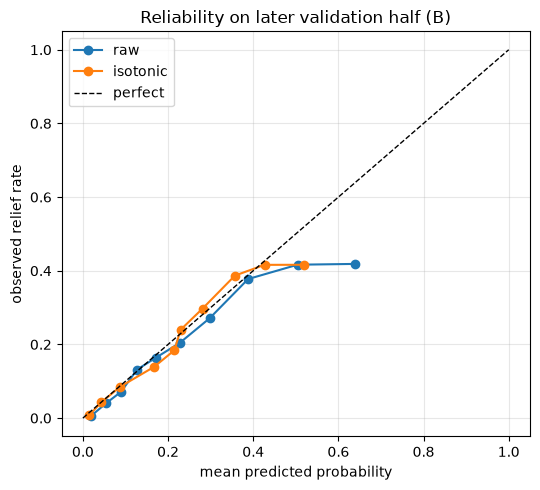

In [32]:
fig, ax = plt.subplots(figsize=(5.5, 5))
if CAL_METHOD != "raw":
    methods_to_plot = ["raw", CAL_METHOD]
else:
    methods_to_plot = ["raw"]
for method in methods_to_plot:
    frac_obs, mean_pred_bin = calibration_curve(yB, np.clip(cal_probs[method], 1e-6, 1 - 1e-6), n_bins=10, strategy="quantile")
    ax.plot(mean_pred_bin, frac_obs, "o-", label=method)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed relief rate")
ax.set_title("Reliability on later validation half (B)")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_reliability.png", dpi=140)
plt.show()

## 12. Decision rule and lift
**Threshold.** If flagging a complaint that ends with relief is worth `BENEFIT_TP` and flagging one that does not costs `COST_FP`, the break-even
probability is `COST_FP / (COST_FP + BENEFIT_TP)`; flag when the **calibrated** probability is above it. The sweep below, on the later half B,
shows what the rule would have delivered.

**Lift.** If reviewers can only handle the top k% of complaints, what share of all relief cases do they catch?

**What this does:** computes the break-even threshold, then tries many thresholds on half B and records how many complaints get flagged, precision
(share of flagged that got relief), recall (share of all relief cases flagged) and net value per complaint.

In [33]:
qB = cal_probs[CAL_METHOD]
t_star = COST_FP / (COST_FP + BENEFIT_TP)
sweep_rows = []
for t in np.round(np.arange(0.05, 0.80, 0.025), 3):
    flag = qB >= t
    tp = int((flag & (yB == 1)).sum())
    fp = int((flag & (yB == 0)).sum())
    sweep_rows.append({"threshold": t, "flagged_share": flag.mean(), "precision": tp / max(tp + fp, 1),
                       "recall": tp / yB.sum(), "net_value_per_complaint": (BENEFIT_TP * tp - COST_FP * fp) / len(yB)})
sweep = pd.DataFrame(sweep_rows)

**What this does:** compares the value of the break-even rule with the two trivial strategies (flag nobody, flag everybody), shows the sweep, and saves it.

In [34]:
tp = int(((qB >= t_star) & (yB == 1)).sum())
fp = int(((qB >= t_star) & (yB == 0)).sum())
v_star = (BENEFIT_TP * tp - COST_FP * fp) / len(yB)
v_all = (BENEFIT_TP * yB.sum() - COST_FP * (len(yB) - yB.sum())) / len(yB)
print(f"break-even threshold {t_star:.3f} -> net value per complaint {v_star:.4f} | flag nobody 0.0000 | flag everybody {v_all:.4f}")
print(f"best swept threshold: {sweep.loc[sweep.net_value_per_complaint.idxmax(), 'threshold']:.3f} "
      f"(value {sweep.net_value_per_complaint.max():.4f})")
display(sweep.iloc[::3])
sweep.to_csv(REPORT_DIR / "04_threshold_sweep.csv", index=False)

break-even threshold 0.250 -> net value per complaint 0.1960 | flag nobody 0.0000 | flag everybody -0.1593
best swept threshold: 0.250 (value 0.1960)


,threshold,flagged_share,precision,recall,net_value_per_complaint
0,0.05,0.8057,0.2551,0.9779,0.0164
3,0.125,0.6752,0.2895,0.9302,0.1068
6,0.2,0.5637,0.3185,0.8542,0.1544
9,0.275,0.3176,0.3991,0.6032,0.1894
12,0.35,0.2772,0.4083,0.5385,0.1755
15,0.425,0.1761,0.4124,0.3455,0.1144
18,0.5,0.02773,0.463,0.06109,0.02363
21,0.575,0.01359,0.5238,0.03388,0.01489
24,0.65,0.01316,0.5328,0.03337,0.01489
27,0.725,0.0005394,0.8,0.002053,0.001187


**What this does:** **lift** compares reviewing the top k% highest-scored complaints with reviewing k% at random. A lift of 2 means twice as many
relief cases per complaint reviewed.

In [35]:
order = np.argsort(-pB, kind="stable")
lift_rows = []
for k in (5, 10, 20, 30, 50):
    n_top = int(len(yB) * k / 100)
    hit = yB[order[:n_top]]
    lift_rows.append({"top_pct_reviewed": k, "precision": hit.mean(), "share_of_all_relief_caught": hit.sum() / yB.sum(),
                      "lift_vs_random": hit.mean() / yB.mean()})
lift_df = pd.DataFrame(lift_rows)
display(lift_df)
lift_df.to_csv(REPORT_DIR / "04_lift_by_top_pct.csv", index=False)

,top_pct_reviewed,precision,share_of_all_relief_caught,lift_vs_random
0,5,0.419,0.09959,1.994
1,10,0.419,0.1992,1.994
2,20,0.4177,0.3973,1.988
3,30,0.4043,0.577,1.924
4,50,0.3375,0.8029,1.606


**What this does:** plots net value against threshold (left) and the share of relief cases caught by reviewing the top k% (right).

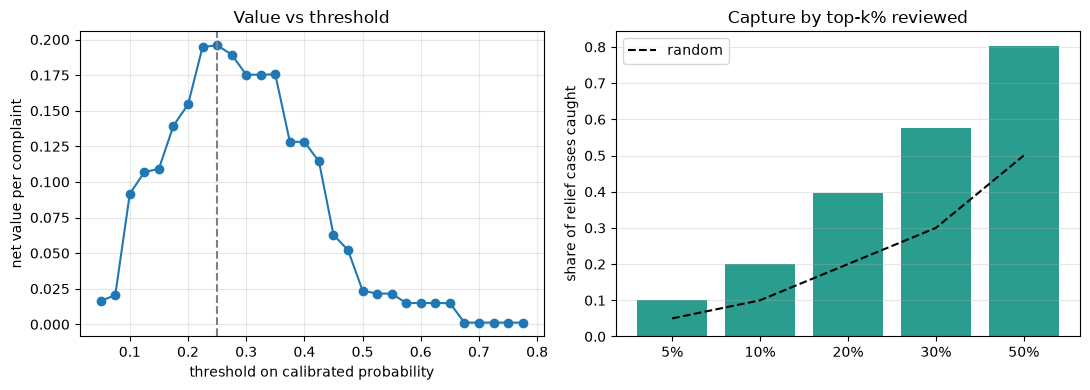

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sweep.threshold, sweep.net_value_per_complaint, "o-")
ax[0].axvline(t_star, ls="--", c="grey")
ax[0].set_xlabel("threshold on calibrated probability")
ax[0].set_ylabel("net value per complaint")
ax[0].set_title("Value vs threshold")
ax[0].grid(alpha=.3)
ax[1].bar(lift_df.top_pct_reviewed.astype(str) + "%", lift_df.share_of_all_relief_caught, color="#2a9d8f")
ax[1].plot(range(len(lift_df)), lift_df.top_pct_reviewed / 100, "k--", label="random")
ax[1].legend()
ax[1].set_ylabel("share of relief cases caught")
ax[1].set_title("Capture by top-k% reviewed")
ax[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_threshold_and_lift.png", dpi=140)
plt.show()

## 13. Explain the boosted model (TreeSHAP)
Exact TreeSHAP contributions come straight from the boosters (the same quantity the `shap` library's `TreeExplainer` returns). Contributions are in
log-odds: positive pushes towards relief. This explains the best **boosted** model even if the logistic model was crowned champion.

**What this does:** **SHAP** splits each prediction into per-feature contributions (how much each input pushed the log-odds up or down). We ask the
boosted model for these directly (`pred_contrib`) on a sample of up to 4000 validation rows, then average their absolute size per feature.

In [37]:
Xs = Fva.sample(min(4000, len(Fva)), random_state=SEED)
if best_boost == "LightGBM":
    contrib = lgbm.booster_.predict(Xs, pred_contrib=True)
else:
    contrib = xgbm.get_booster().predict(xgb.DMatrix(Xs, enable_categorical=True), pred_contribs=True)
contrib = np.asarray(contrib)[:, :-1]   # last column is the model's base value, not a feature
imp = pd.Series(np.abs(contrib).mean(axis=0), index=Xs.columns).sort_values(ascending=False)
display(imp.to_frame("mean_abs_shap"))
imp.to_frame("mean_abs_shap").to_csv(REPORT_DIR / "04_shap_importance.csv")

,mean_abs_shap
text_score,0.9667
issue,0.1874
product_group,0.1135
log_words,0.02291
n_amounts,0.0138


**What this does:** plots the feature importances (left) and how the text score changes the prediction (right).

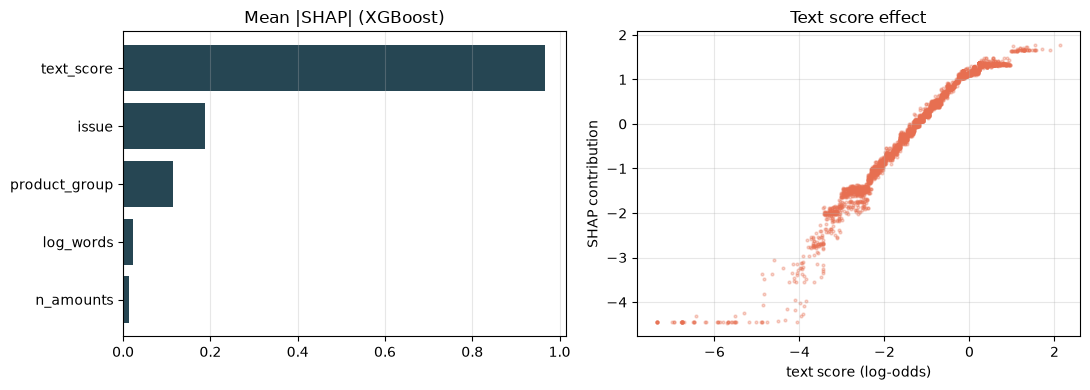

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(imp.index[::-1], imp.values[::-1], color="#264653")
ax[0].set_title(f"Mean |SHAP| ({best_boost})")
ax[0].grid(axis="x", alpha=.3)
j = list(Xs.columns).index("text_score")
ax[1].scatter(Xs.text_score, contrib[:, j], s=4, alpha=.3, color="#e76f51")
ax[1].set_xlabel("text score (log-odds)")
ax[1].set_ylabel("SHAP contribution")
ax[1].set_title("Text score effect")
ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_shap.png", dpi=140)
plt.show()

**What this does:** an optional cross-check against the `shap` library; the difference should be tiny. It is skipped if the library is not installed.

In [39]:
try:
    import shap
    if best_boost == "LightGBM":
        explainer = shap.TreeExplainer(lgbm)
    else:
        explainer = shap.TreeExplainer(xgbm)
    sv = explainer.shap_values(Xs)
    if isinstance(sv, list):
        sv = sv[1]
    print("max |native - shap library| =", float(np.abs(np.asarray(sv) - contrib).max()))
except Exception as e:
    print("shap library cross-check skipped:", type(e).__name__)

d:\Resume\Data Scientist\Resume_Projects\BankSight_Consumer Complaint Intelligence Platform\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max |native - shap library| = 0.0


## 14. Log to MLflow and save artefacts
One MLflow run per model, stored locally in `mlflow.db` (SQLite) next to the project. To browse it, open a terminal in the project folder and run
`mlflow ui --backend-store-uri sqlite:///mlflow.db`, then open http://127.0.0.1:5000. MLflow problems never stop the notebook.

**What this does:** collects every decision made in this notebook (champion, threshold, calibration, tuned settings) into one dictionary and saves
it as `04_decisions.json`.

In [40]:
lightgbm_params = dict(best_lgb_params)
lightgbm_params["n_estimators"] = n_l
xgboost_params = dict(best_xgb_params)
xgboost_params["n_estimators"] = n_x
decisions = {
    "champion": CHAMPION, "champion_rule": why, "best_boosted": best_boost, "text_C": BEST_C,
    "calibration": CAL_METHOD, "cost_fp": COST_FP, "benefit_tp": BENEFIT_TP, "threshold": t_star,
    "company_mask_share_of_text_lift_retained": None if np.isnan(retained) else float(retained),
    "lightgbm_params": lightgbm_params, "xgboost_params": xgboost_params,
}
(REPORT_DIR / "04_decisions.json").write_text(json.dumps(decisions, indent=2))

825

**What this does:** **MLflow** is an experiment tracker. This logs one run per model (settings and metrics) plus a run holding the decisions file
and figures. Everything is wrapped in `try/except`, so a tracking problem never stops the notebook.

In [41]:
try:
    import mlflow
    db = (ROOT.resolve() / "mlflow.db").as_posix()
    mlflow.set_tracking_uri(f"sqlite:///{db}")
    exp_name = "banksight_relief"
    if mlflow.get_experiment_by_name(exp_name) is None:
        mlflow.create_experiment(exp_name, artifact_location=(ROOT.resolve() / "mlartifacts").as_uri())
    mlflow.set_experiment(exp_name)
    for name, r in res.iterrows():
        params_to_log = {"split": "train->validation", "text_C": BEST_C}
        if name == "LightGBM":
            params_to_log.update(decisions["lightgbm_params"])
        elif name == "XGBoost":
            params_to_log.update(decisions["xgboost_params"])
        with mlflow.start_run(run_name=name):
            mlflow.log_params(params_to_log)
            mlflow.log_metrics({"pr_auc": float(r["pr_auc"]), "roc_auc": float(r["roc_auc"]),
                                "within_product_roc_auc": float(r["within_product_roc_auc"]), "brier": float(r["brier"])})
            mlflow.set_tag("is_champion", str(name == CHAMPION))
    with mlflow.start_run(run_name="decisions"):
        mlflow.log_artifact(str(REPORT_DIR / "04_decisions.json"))
        for fig_name in ("04_reliability.png", "04_threshold_and_lift.png", "04_shap.png"):
            mlflow.log_artifact(str(FIG_DIR / fig_name))
    print("MLflow runs logged to", db)
except Exception as e:
    print("MLflow logging skipped:", type(e).__name__, str(e)[:200])

MLflow runs logged to D:/Resume/Data Scientist/Resume_Projects/BankSight_Consumer Complaint Intelligence Platform/mlflow.db


**What this does:** saves everything notebook 05 needs into one file: the fitted models, vectorizer, encoder, category lists, calibrators, threshold
and the cleaning patterns. The key names must not change.

In [42]:
joblib.dump({
    "decisions": decisions, "champion": CHAMPION, "tfidf": tfidf, "text_model": text_full, "ohe": ohe, "b4_model": b4,
    "lightgbm": lgbm, "xgboost": xgbm, "issue_cats": ISSUE_CATS, "product_cats": PRODUCT_CATS,
    "calibration": {"method": CAL_METHOD, "platt": platt, "isotonic": iso}, "threshold": t_star,
    "clean_patterns": [RE_AMT, RE_DATE, RE_MASK],
}, MODEL_DIR / "04_champion_bundle.joblib", compress=3)
print("saved", MODEL_DIR / "04_champion_bundle.joblib")
print("reports:", *sorted(p.name for p in REPORT_DIR.glob("04_*")), sep="\n  ")

saved ..\models\04_champion_bundle.joblib
reports:
  04_calibration.csv
  04_decisions.json
  04_lift_by_top_pct.csv
  04_model_comparison_validation.csv
  04_paired_bootstrap.csv
  04_search_lightgbm.csv
  04_search_xgboost.csv
  04_shap_importance.csv
  04_threshold_sweep.csv
  04_tuning_text_C.csv
